<a href="https://colab.research.google.com/github/smir-nat/IAD-Practicals/blob/main/lab2/lab_2_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Завдання 1

Кількість ознак ДО зниження розмірності: 7
Кількість ознак ПІСЛЯ PCA: 6

--- Порівняння результатів ---
ДО PCA   | F1-Score: 0.5000 | Час навчання: 0.0746 сек
ПІСЛЯ PCA| F1-Score: 0.1646 | Час навчання: 0.1396 сек


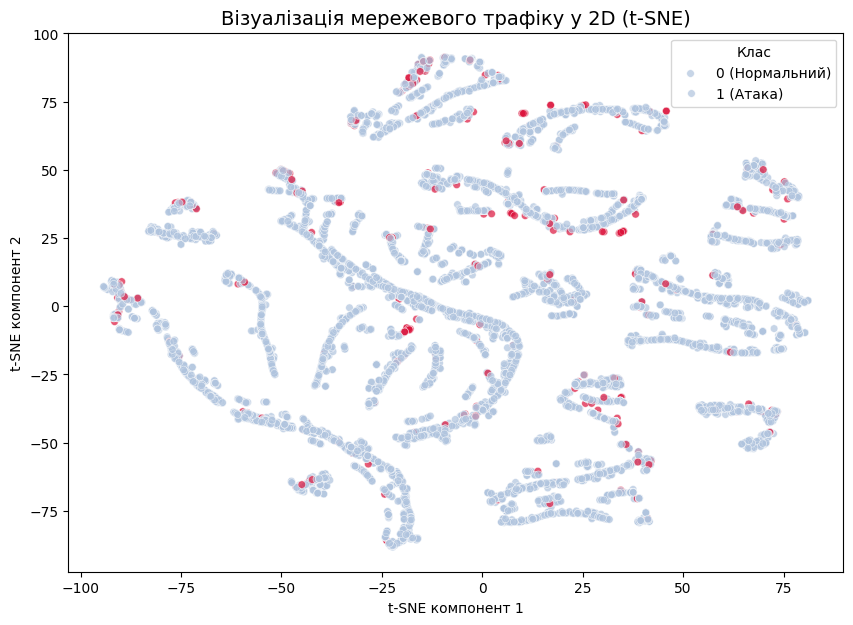

In [4]:
import pandas as pd
import numpy as np
import time
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import classification_report, f1_score

url = 'https://raw.githubusercontent.com/smir-nat/IAD-Practicals/main/lab2/cybersecurity.csv'
df = pd.read_csv(url)

cols_to_drop = ['timestamp', 'src_ip', 'dst_ip', 'url', 'attack_type']
df_clean = df.drop(columns=cols_to_drop)

le = LabelEncoder()
df_clean['protocol'] = le.fit_transform(df_clean['protocol'])
df_clean['user_agent'] = le.fit_transform(df_clean['user_agent'])
df_clean['is_internal_traffic'] = df_clean['is_internal_traffic'].astype(int)

X = df_clean.drop(columns=['label'])
y = df_clean['label']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Кількість ознак ДО зниження розмірності: {X_train.shape[1]}")

dt_base = DecisionTreeClassifier(random_state=42)
start_time = time.time()
dt_base.fit(X_train_scaled, y_train)
time_base = time.time() - start_time
y_pred_base = dt_base.predict(X_test_scaled)
f1_base = f1_score(y_test, y_pred_base)

pca = PCA(n_components=0.95, random_state=42)
X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

print(f"Кількість ознак ПІСЛЯ PCA: {X_train_pca.shape[1]}")

dt_pca = DecisionTreeClassifier(random_state=42)
start_time = time.time()
dt_pca.fit(X_train_pca, y_train)
time_pca = time.time() - start_time
y_pred_pca = dt_pca.predict(X_test_pca)
f1_pca = f1_score(y_test, y_pred_pca)

print("\n--- Порівняння результатів ---")
print(f"ДО PCA   | F1-Score: {f1_base:.4f} | Час навчання: {time_base:.4f} сек")
print(f"ПІСЛЯ PCA| F1-Score: {f1_pca:.4f} | Час навчання: {time_pca:.4f} сек")

tsne = TSNE(n_components=2, random_state=42)
X_tsne = tsne.fit_transform(X_train_scaled)

plt.figure(figsize=(10, 7))
sns.scatterplot(
    x=X_tsne[:, 0], y=X_tsne[:, 1],
    hue=y_train,
    palette={0: 'lightsteelblue', 1: 'crimson'},
    alpha=0.7, s=30
)
plt.title('Візуалізація мережевого трафіку у 2D (t-SNE)', fontsize=14)
plt.xlabel('t-SNE компонент 1')
plt.ylabel('t-SNE компонент 2')
plt.legend(title='Клас', labels=['0 (Нормальний)', '1 (Атака)'])
plt.show()

Завдання 2

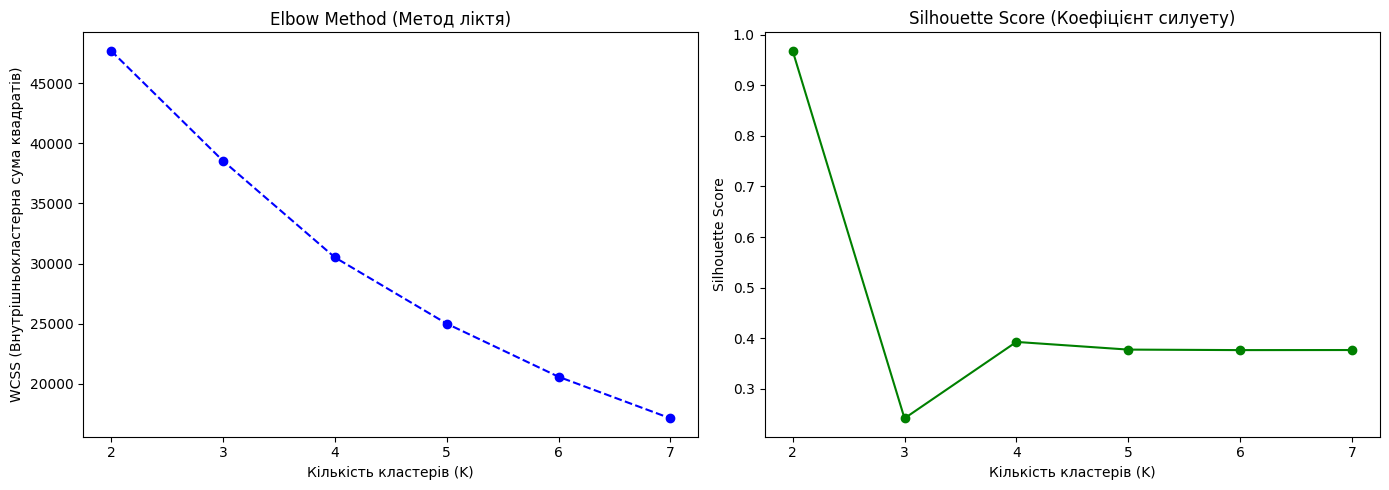

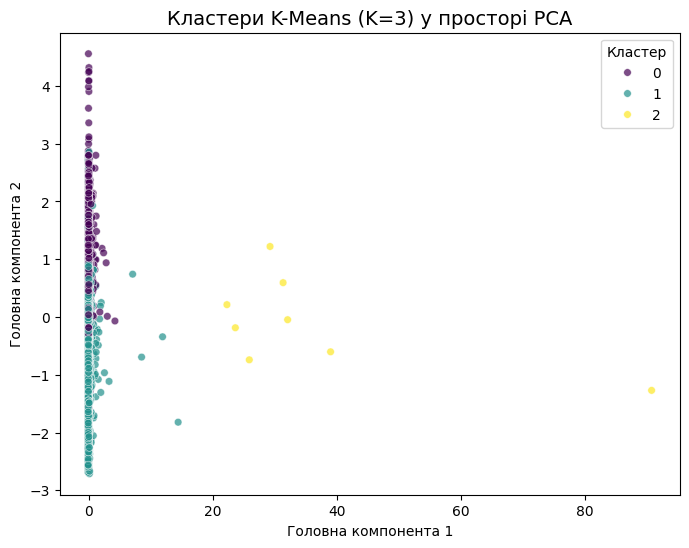


--- Порівняння знайдених кластерів зі справжніми класами ---
Рядки (0, 1) - Справжні мітки (Нормальний трафік, Атака)
Стовпці (0, 1, 2) - Знайдені кластери K-Means

Знайдений Кластер     0     1  2
Справжній Клас                  
0                  2397  5283  0
1                   134   178  8


In [6]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

X_unsupervised = X_train_scaled
y_true = y_train

wcss = []
silhouette_scores = []
K_range = range(2, 8)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    cluster_labels = kmeans.fit_predict(X_unsupervised)
    wcss.append(kmeans.inertia_)
    silhouette_scores.append(silhouette_score(X_unsupervised, cluster_labels))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(K_range, wcss, marker='o', linestyle='--', color='b')
axes[0].set_title('Elbow Method (Метод ліктя)')
axes[0].set_xlabel('Кількість кластерів (K)')
axes[0].set_ylabel('WCSS (Внутрішньокластерна сума квадратів)')

axes[1].plot(K_range, silhouette_scores, marker='o', linestyle='-', color='g')
axes[1].set_title('Silhouette Score (Коефіцієнт силуету)')
axes[1].set_xlabel('Кількість кластерів (K)')
axes[1].set_ylabel('Silhouette Score')

plt.tight_layout()
plt.show()

optimal_k = 3
kmeans_final = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
final_clusters = kmeans_final.fit_predict(X_unsupervised)

pca = PCA(n_components=2, random_state=42)
X_pca_2d = pca.fit_transform(X_unsupervised)

plt.figure(figsize=(8, 6))
sns.scatterplot(
    x=X_pca_2d[:, 0], y=X_pca_2d[:, 1],
    hue=final_clusters,
    palette='viridis',
    alpha=0.7, s=30
)
plt.title(f'Кластери K-Means (K={optimal_k}) у просторі PCA', fontsize=14)
plt.xlabel('Головна компонента 1')
plt.ylabel('Головна компонента 2')
plt.legend(title='Кластер')
plt.show()

comparison_df = pd.DataFrame({'Справжній Клас': y_true, 'Знайдений Кластер': final_clusters})
crosstab_result = pd.crosstab(comparison_df['Справжній Клас'], comparison_df['Знайдений Кластер'])

print("\n--- Порівняння знайдених кластерів зі справжніми класами ---")
print("Рядки (0, 1) - Справжні мітки (Нормальний трафік, Атака)")
print("Стовпці (0, 1, 2) - Знайдені кластери K-Means\n")
print(crosstab_result)

Завдання 3

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


Розподіл класів у текстовому датасеті:
label
ham     4825
spam     747
Name: count, dtype: int64


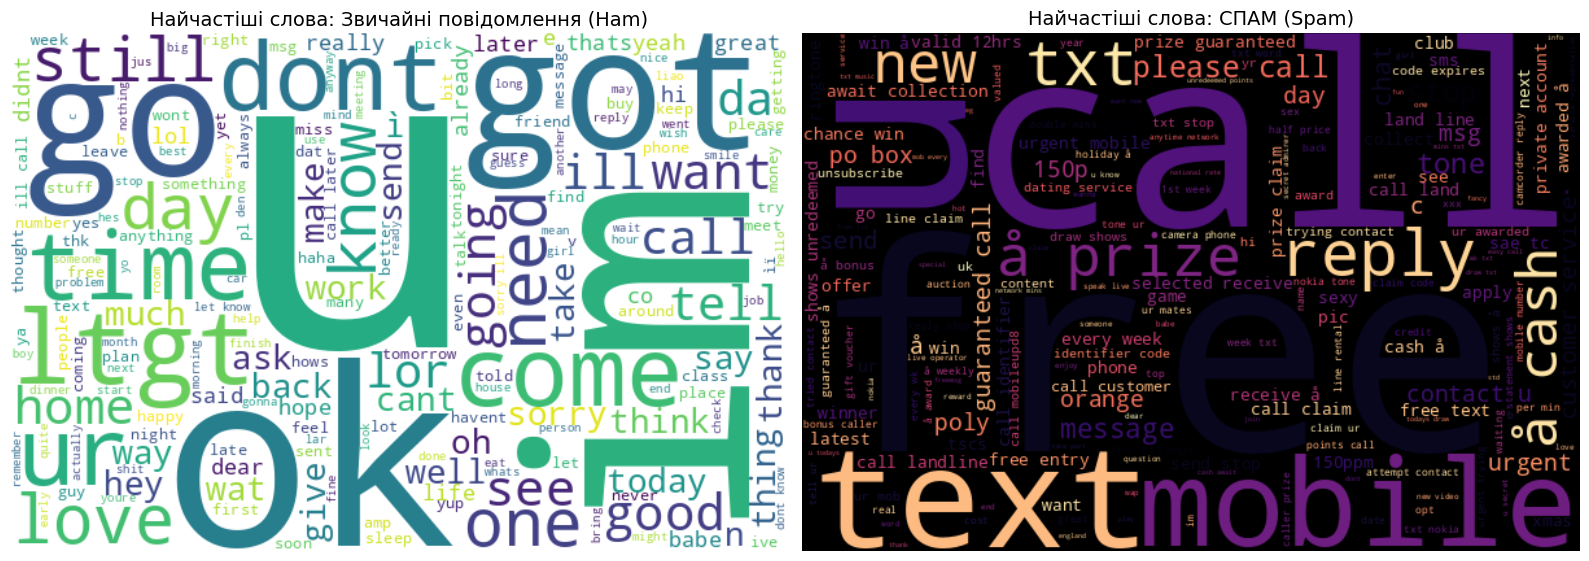


--- Результати класифікації текстів (Multinomial Naive Bayes) ---
              precision    recall  f1-score   support

         ham       0.97      1.00      0.99       965
        spam       1.00      0.83      0.91       150

    accuracy                           0.98      1115
   macro avg       0.99      0.91      0.95      1115
weighted avg       0.98      0.98      0.98      1115



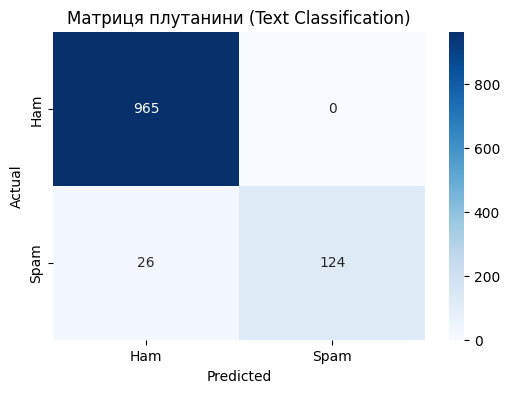

In [8]:
import pandas as pd
import string
import matplotlib.pyplot as plt
from wordcloud import WordCloud
import nltk
from nltk.corpus import stopwords
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

nltk.download('stopwords')
stop_words = set(stopwords.words('english'))

url = 'https://raw.githubusercontent.com/mohitgupta-omg/Kaggle-SMS-Spam-Collection-Dataset-/master/spam.csv'
df_text = pd.read_csv(url, encoding='latin-1')
df_text = df_text[['v1', 'v2']]
df_text.columns = ['label', 'text']

print("Розподіл класів у текстовому датасеті:")
print(df_text['label'].value_counts())

def preprocess_text(text):
    text = text.lower()
    text = text.translate(str.maketrans('', '', string.punctuation))
    words = text.split()
    words = [w for w in words if w not in stop_words]
    return ' '.join(words)

df_text['clean_text'] = df_text['text'].apply(preprocess_text)

spam_words = ' '.join(df_text[df_text['label'] == 'spam']['clean_text'])
ham_words = ' '.join(df_text[df_text['label'] == 'ham']['clean_text'])

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

wordcloud_ham = WordCloud(width=600, height=400, background_color='white', colormap='viridis').generate(ham_words)
axes[0].imshow(wordcloud_ham, interpolation='bilinear')
axes[0].set_title('Найчастіші слова: Звичайні повідомлення (Ham)', fontsize=14)
axes[0].axis('off')

wordcloud_spam = WordCloud(width=600, height=400, background_color='black', colormap='magma').generate(spam_words)
axes[1].imshow(wordcloud_spam, interpolation='bilinear')
axes[1].set_title('Найчастіші слова: СПАМ (Spam)', fontsize=14)
axes[1].axis('off')

plt.tight_layout()
plt.show()

X_train, X_test, y_train, y_test = train_test_split(df_text['clean_text'], df_text['label'], test_size=0.2, random_state=42)

tfidf = TfidfVectorizer(max_features=3000)
X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

model_nb = MultinomialNB()
model_nb.fit(X_train_tfidf, y_train)
y_pred = model_nb.predict(X_test_tfidf)

print("\n--- Результати класифікації текстів (Multinomial Naive Bayes) ---")
print(classification_report(y_test, y_pred))

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Ham', 'Spam'], yticklabels=['Ham', 'Spam'])
plt.title('Матриця плутанини (Text Classification)')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()